# Puntos descartados con cirrus + otra causa en la ventana

Ejemplos de los puntos `pocos_pixeles_buenos` que tienen `CIRRUS` y ademas otra bandera (distinta de `NO_AGUA`) en la ventana 5x5.
En los 550 casos solo aparecen `MUY_BRILLANTE` (525), `FUERA_ESCENA` (150) y `REFL_NEGATIVA` (1); no hay `SOMBRA` ni `MIXTO`.

Paneles: color natural con la ventana 5x5 en rojo | `l2_flags` por bit | `rhot_1373` (banda de cirrus, umbral 0.005).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))

from viz.acolite import visualizar_ventana

import numpy as np
import pandas as pd

from core.ac_tools import dist_punto_pixeles, open_l2w
from core.s3 import DEFAULT_BUCKET, get_s3_client
from tools.ac.extract_windows import ACOLITE_SAVE_DIR, half
from dotenv import load_dotenv
import xarray as xr

load_dotenv(ROOT / ".env")
ACOLITE_SAVE_DIR = ROOT / ACOLITE_SAVE_DIR

df = pd.read_csv(ROOT / "data/nuevos/matchups_ventanas.csv", index_col="matchup_index")

# matchup_index de cada ejemplo
ejemplos = {
    "cirrus + muy brillante": [916, 1024, 135],
    "cirrus + fuera de escena": [2507],
}


In [2]:
def l2r_de(l2w_path, s3, bucket=DEFAULT_BUCKET):
    # el L2R esta junto al L2W en s3; se baja si no esta
    l2r = l2w_path.with_name(l2w_path.name.replace("L2W", "L2R"))
    if not l2r.exists():
        parte = l2w_path.parent.name if l2w_path.parent.name.startswith("parte") else None
        pass_id = l2w_path.parent.parent.name if parte else l2w_path.parent.name
        key = "/".join(["acolite", pass_id] + ([parte] if parte else []) + [l2r.name])
        s3.download_file(bucket, key, str(l2r))
    return xr.open_dataset(l2r).load()


def buscar(p, pass_id):
    # parte (L2W) con el pixel mas cercano al punto
    mejor = None
    for path in sorted((ACOLITE_SAVE_DIR / pass_id).glob("**/*L2W.nc")):
        dl = open_l2w(path)
        d2 = dist_punto_pixeles(p, dl["lat"].values, dl["lon"].values)
        i, j = np.unravel_index(np.nanargmin(d2), d2.shape)
        if mejor is None or d2[i, j] < mejor[0]:
            mejor = (d2[i, j], i, j, path, dl)
    return mejor[1:]

[cirrus + muy brillante] matchup 916  S2B_MSIL1C_20201113T133229_N0500_R081_T21HXB_20230410T192114  grupo LDS
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'CIRRUS': 25, 'MUY_BRILLANTE': 25}   buenos: 0


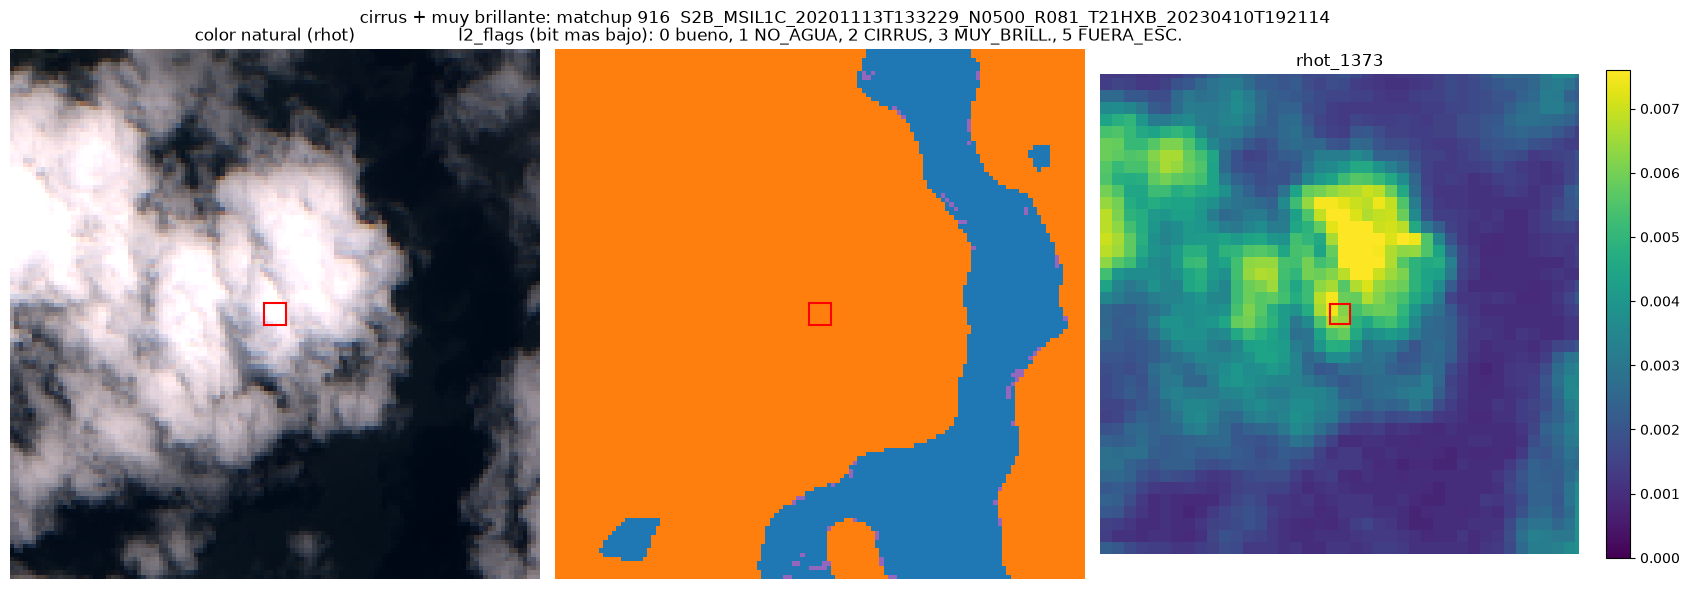

[cirrus + muy brillante] matchup 1024  S2A_MSIL1C_20210209T134211_N0500_R124_T21HXB_20230605T164612  grupo LDS
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'CIRRUS': 13, 'MUY_BRILLANTE': 25}   buenos: 0


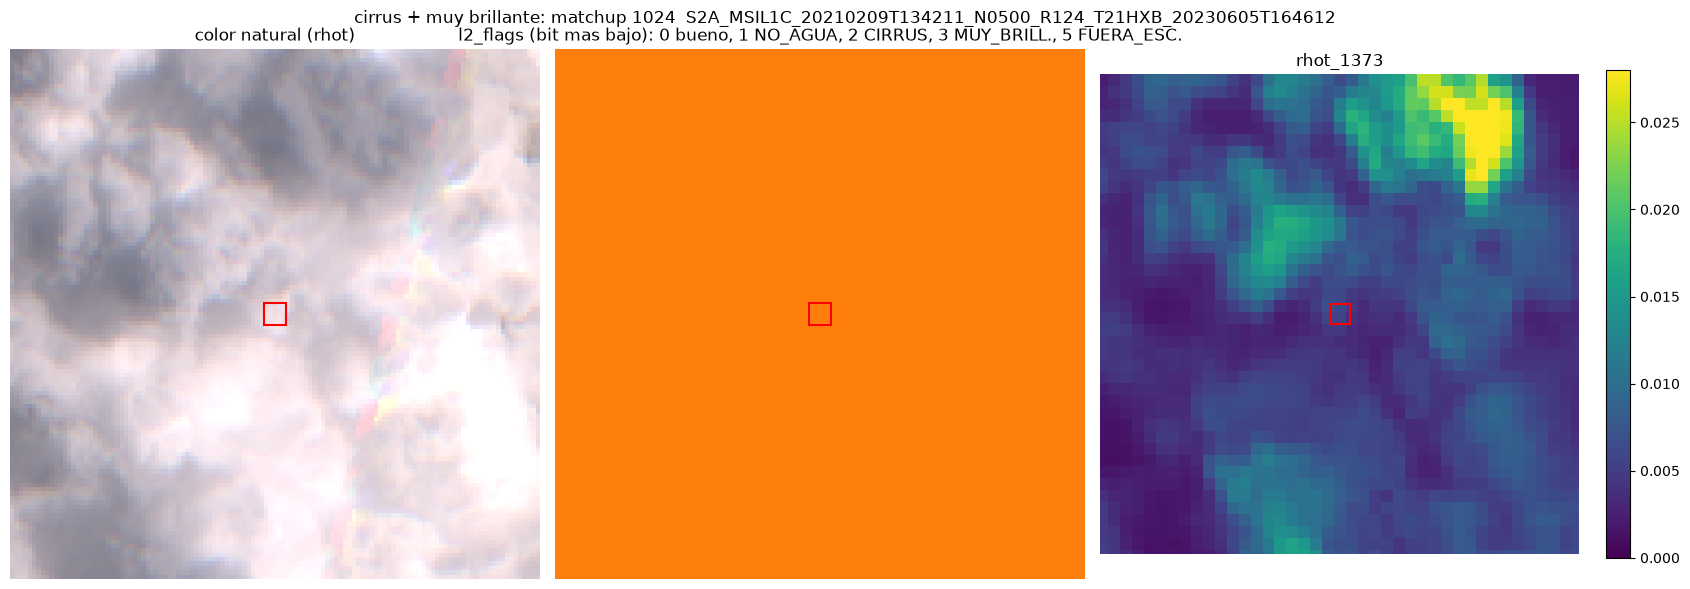

[cirrus + muy brillante] matchup 135  S2A_MSIL1C_20170404T135111_N0500_R024_T21HUC_20230925T141242  grupo RDP-MONTES
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'CIRRUS': 25, 'MUY_BRILLANTE': 25}   buenos: 0


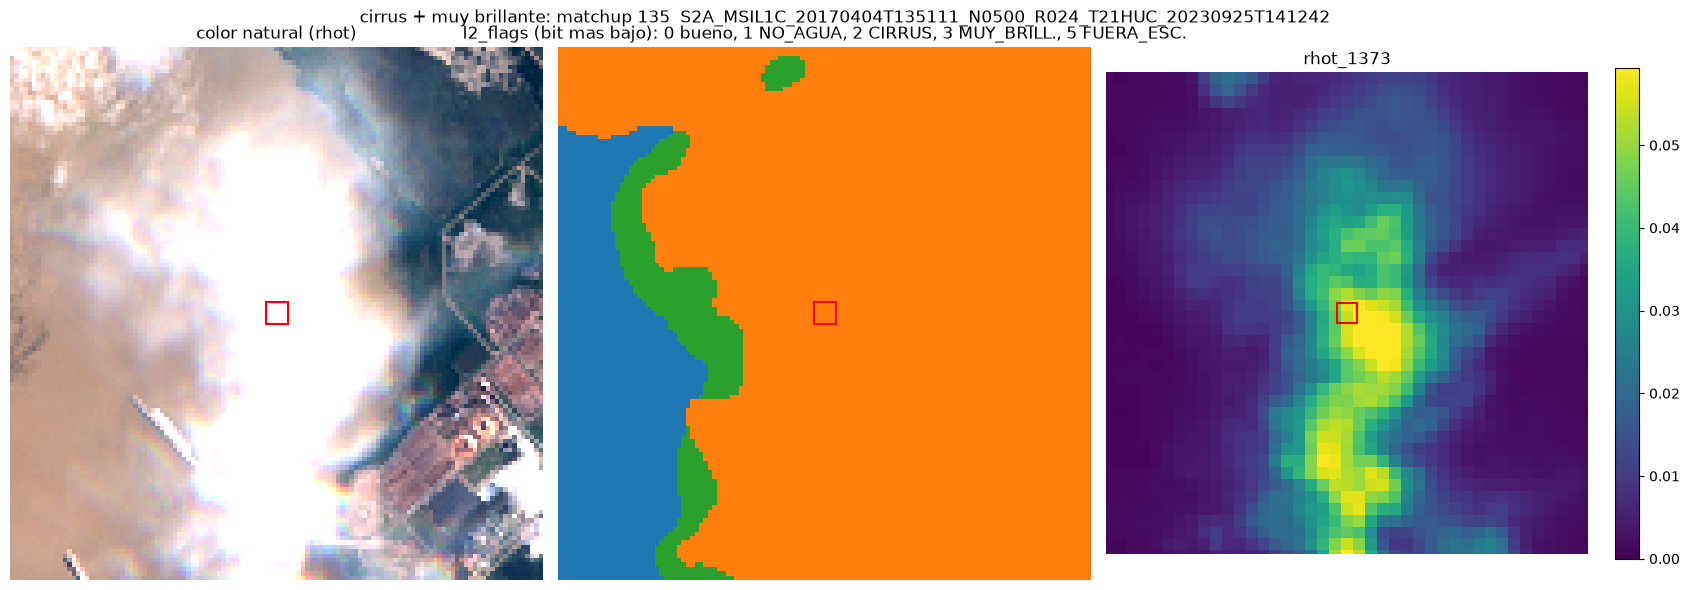

[cirrus + fuera de escena] matchup 2507  S2A_MSIL1C_20240108T134701_N0510_R024_T21HWD_20240108T171018  grupo RN-UPM2
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'CIRRUS': 25, 'FUERA_ESCENA': 25}   buenos: 0


/home/enzotrindade/ProyectoAA/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


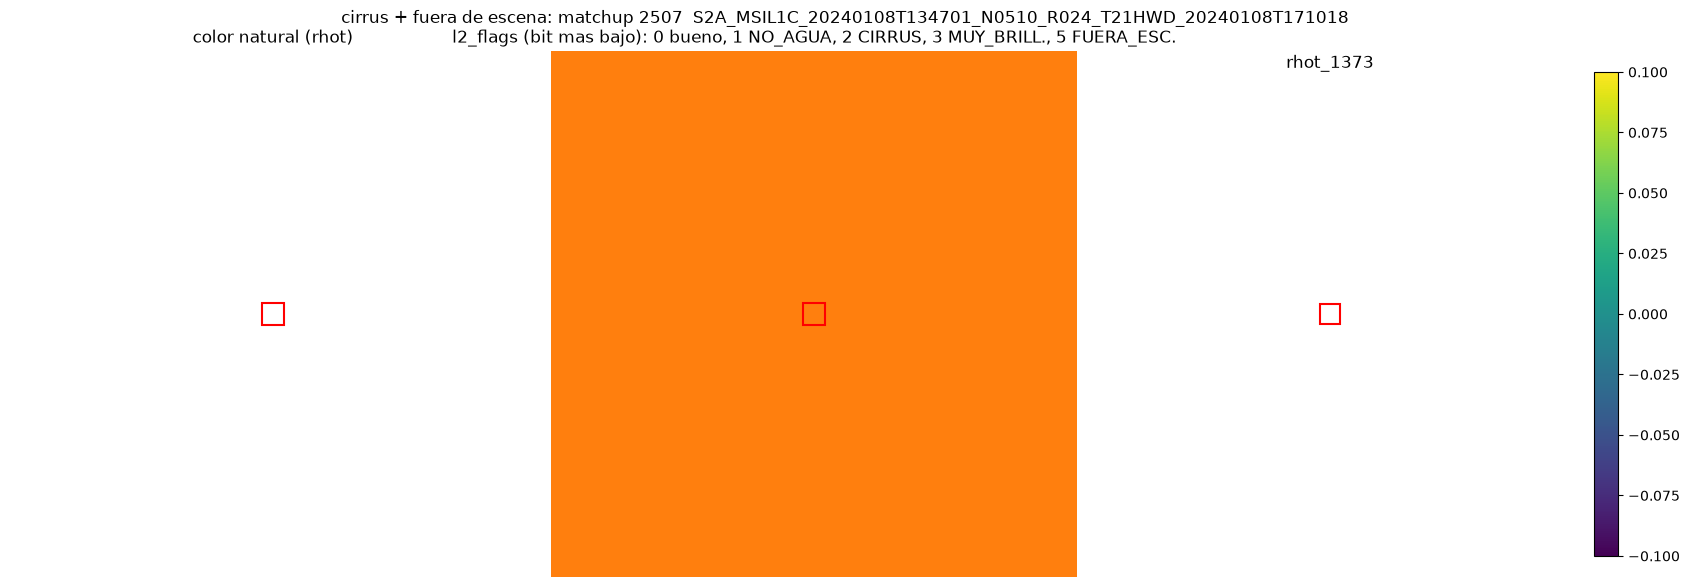

In [3]:
s3 = get_s3_client()
R = 60  # recorte: +-R pixeles alrededor del punto

for causa, idxs in ejemplos.items():
    for idx in idxs:
        p = df.loc[idx]
        i, j, path, w = buscar(p, p["pass_id"])
        r = l2r_de(path, s3)

        visualizar_ventana(
            r, w, i, j, causa=causa, idx=idx, pass_id=p["pass_id"],
            grupo_nombre=p["grupo_nombre"], radio=R, half=half,
            longitud_onda=1373, percentil=99,
        )
